# XGBoosting Algorithm for steel calssification with Augmented Data


In [34]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from matplotlib.lines import Line2D
import numpy as np

## 1. Augmented Data from WGAN

In [35]:
# downsample St 48
original_data = pd.read_csv("../../labeled_OES_data_2.csv")
original_data_copy = original_data.copy()
deleting_number = 300
print(original_data.shape)
for index, row in original_data.iterrows():
    if row.iloc[-1] == "St 48" and deleting_number > 0:
        original_data.drop(index, inplace=True)
        deleting_number -= 1
print(original_data.shape)

(1429, 10)
(1129, 10)


In [36]:
classes_dict = {"St 48" : 0, "St 37" : 1, "St Si" : 2, "St 48-TH" : 3, "Puddelstahl" : 4}
st37_data = pd.read_csv("WGAN_Augmented_St37_XGB.csv")
st48_TH_data = pd.read_csv("WGAN_Augmented_St48_TH_XGB.csv")

st37_data["steel_class"] = "St 37"
st48_TH_data["steel_class"] = "St 48-TH"

data = pd.concat([original_data, st37_data, st48_TH_data])

data["steel_class"] = [classes_dict[c] for c in data["steel_class"] ]    

# make data numeric
for column in data.columns:
        for index, value in data[column].items():
            if isinstance(value, str):
                data.at[index, column] = value.replace(",", ".")
data = data.map(pd.to_numeric)
data.shape

(1286, 10)

Group Name: St 48
(527, 10)
Group Name: St 37
(326, 10)
Group Name: St Si
(79, 10)
Group Name: St 48-TH
(149, 10)
Group Name: Puddelstahl
(205, 10)


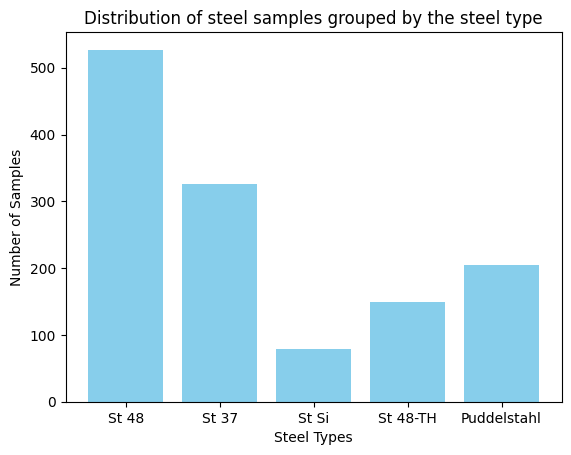

In [37]:
grouped_data = data.groupby("steel_class")
number_of_samples_group = []

for group_id, gdata in grouped_data:
    for key, val in classes_dict.items():
        if val == group_id:
            group_name = key
    print("Group Name:", group_name)
    print(gdata.shape)
    number_of_samples_group.append(gdata.shape[0])
    
steel_type_names = classes_dict.keys()

plt.bar(steel_type_names, number_of_samples_group, color='skyblue')

plt.xlabel('Steel Types')
plt.ylabel('Number of Samples')
plt.title('Distribution of steel samples grouped by the steel type')

#plt.savefig('distribution_samples_steeltypes.jpg', format='jpg')
plt.show()

In [38]:
# create X and y
X = data.drop(columns="steel_class")
y = data["steel_class"]


# create training and testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [39]:
# Given are steel types: St48, St 37, StSi, St 48-TH, Puddelstahl -> num_class = 5
# Note: in our Project num_classes is dependent on the supplied file which is used to train the model

# create Classifier
model = xgb.XGBClassifier(objective="multi:softmax", num_class=5, n_estimators=200, max_depth=2, learning_rate=0.01, gamma=0, reg_lambda=0)
model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=0, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.01, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=2, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None, num_class=5,
              num_parallel_tree=None, ...)

In [40]:
previously_misclassified_index = [332, 334, 461, 462, 631, 712, 714, 777, 798, 812, 814, 1182, 1368]
previously_misclassified = original_data_copy.iloc[previously_misclassified_index]


# make data numeric
for column in previously_misclassified.columns:
        for index, value in previously_misclassified[column].items():
            if isinstance(value, str):
                previously_misclassified.at[index, column] = value.replace(",", ".")

previously_misclassified.loc[:, "steel_class"] = [classes_dict[c] for c in previously_misclassified["steel_class"] ]    

previously_misclassified = previously_misclassified.map(pd.to_numeric)
previously_misclassified.head()

,C,Si,Mn,P,S,Cr,Ni,Al,Cu,steel_class
332,0.309167,0.009233,0.430333,0.030550,0.028483,0.0050,0.029417,0.002000,0.059017,0
334,0.051400,0.005000,0.472500,0.007967,0.018300,0.0127,0.052150,0.002000,0.139167,1
461,0.220000,0.005000,0.574667,0.053267,0.034067,0.0050,0.024333,0.008517,0.034167,1
462,0.223250,0.005000,0.559750,0.055075,0.031350,0.0050,0.021800,0.009025,0.033425,1
631,0.171700,0.129400,0.627100,0.027800,0.029600,0.0146,0.037600,0.023100,0.106800,1


<br>

In [41]:
previous_label = previously_misclassified.iloc[:, -1]
previously_misclassified_unlabeled = previously_misclassified.iloc[:, :-1]

In [42]:
n_prediction = model.predict(previously_misclassified_unlabeled)
correct = 0
for i in range(len(n_prediction)):
    print("Prediction: ", n_prediction[i], " - ", "GT: ", previous_label.iloc[i])
    if n_prediction[i] == previous_label.iloc[i]:
        correct += 1
print("In total correct: ", correct)

Prediction:  3  -  GT:  0
Prediction:  1  -  GT:  1
Prediction:  3  -  GT:  1
Prediction:  3  -  GT:  1
Prediction:  0  -  GT:  1
Prediction:  1  -  GT:  3
Prediction:  1  -  GT:  3
Prediction:  0  -  GT:  0
Prediction:  0  -  GT:  1
Prediction:  3  -  GT:  3
Prediction:  1  -  GT:  3
Prediction:  1  -  GT:  1
Prediction:  4  -  GT:  4
In total correct:  5


<br>

In [43]:
score_array = cross_val_score(xgb.XGBClassifier(objective="multi:softmax", num_class=5, n_estimators=200, max_depth=2, learning_rate=0.01, gamma=0, reg_lambda=0), X, y, cv=9)

sum(score_array)/len(score_array)

0.9137310264070828

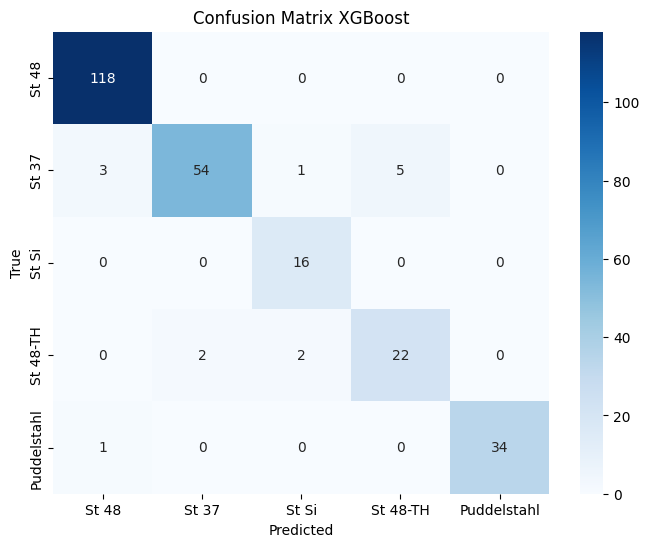

In [44]:
# build Confusion Matrix
predictions = model.predict(X_test)
conf_matrix = confusion_matrix(y_test, predictions)
{"St 48" : 0, "St 37" : 1, "St Si" : 2, "St 48-TH" : 3, "Puddelstahl" : 4}
# print Confusion Martix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"], yticklabels=["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix XGBoost')
#plt.savefig('Confusion_Matrix_XGBoost_Augmented.jpg', format='jpg')

plt.show()

In [45]:
new_labels = ["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"]
report = classification_report(y_test, predictions, target_names=new_labels)

print(report)

              precision    recall  f1-score   support

       St 48       0.97      1.00      0.98       118
       St 37       0.96      0.86      0.91        63
       St Si       0.84      1.00      0.91        16
    St 48-TH       0.81      0.85      0.83        26
 Puddelstahl       1.00      0.97      0.99        35

    accuracy                           0.95       258
   macro avg       0.92      0.93      0.92       258
weighted avg       0.95      0.95      0.95       258



Misclassified Samples

In [46]:
# Extract misclassified data samples
row_numbers = []
for i in range(len(predictions)):
    if predictions[i] != y_test.iloc[i]:
        row_numbers.append(i)

print(row_numbers)

wrong_rows = X_test.iloc[row_numbers].copy()
wrong_rows.loc[:,"steel_type_true"] = y_test.iloc[row_numbers]
wrong_rows.loc[:,"steel_type_predicted"] = predictions[row_numbers]

print(wrong_rows)

[5, 26, 37, 47, 57, 92, 111, 127, 152, 177, 193, 216, 223, 250]
             C        Si        Mn         P         S        Cr        Ni  \
1225  0.208000  0.170000  0.141000  0.067000  0.013000  0.005000  0.028000   
814   0.108000  0.009700  0.565000  0.025400  0.026200  0.021400  0.043100   
14    0.097000  0.975000  0.675000  0.026000  0.035000  0.009000  0.043000   
219   0.175167  0.005000  0.501333  0.011567  0.032567  0.009817  0.036667   
40    0.476470  0.028096  0.255618  0.028098  0.028797  0.022538  0.038706   
37    0.061000  0.005000  0.312000  0.020000  0.035000  0.025000  0.047000   
725   0.158000  0.133000  0.514000  0.012300  0.061400  0.005000  0.047700   
631   0.171700  0.129400  0.627100  0.027800  0.029600  0.014600  0.037600   
842   0.180000  0.010000  0.500000  0.017000  0.043000  0.010000  0.040000   
468   0.180500  0.012200  0.439500  0.011200  0.020425  0.005000  0.052875   
238   0.185667  0.007467  0.560333  0.030378  0.033033  0.029833  0.036256   


**All rows with an index > 1129 are augmented samples**

(14, 9)


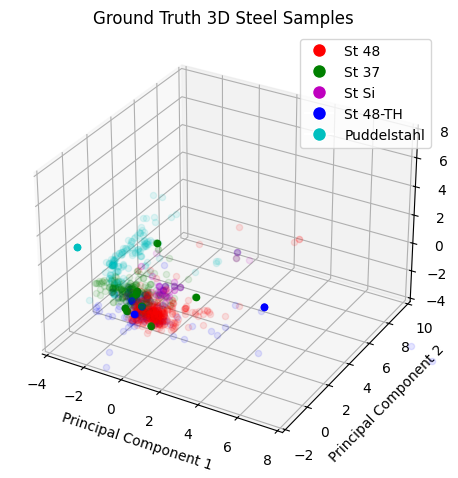

In [47]:
wrong_rows = wrong_rows.iloc[:, :-2]
print(wrong_rows.shape)
scaler = StandardScaler()
scaled_wrong_rows = scaler.fit_transform(wrong_rows)

pca = PCA(3)
pca_wrong_rows = pca.fit_transform(scaled_wrong_rows)

training_data = X_train
scaled_training_data = scaler.fit_transform(training_data)
pca_training_data = pca.fit_transform(scaled_training_data)

x = pca_wrong_rows[:, 0]
y = pca_wrong_rows[:, 1]
z = pca_wrong_rows[:, 2]

x_tr = pca_training_data[:, 0]
y_tr = pca_training_data[:, 1]
z_tr = pca_training_data[:, 2]

true_categories = y_test.iloc[row_numbers]
train_categories = y_train

rev_classes_dict = {0: "St 48", 1 : "St 37", 2 : "St Si", 3 : "St 48-TH", 4 : "Puddelstahl"}


class_colors = ['r', 'g', 'm', 'b', 'c']
classes = [0, 1, 2, 3, 4]

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

for i in range(len(x)):
        ax.scatter(x[i], y[i], z[i], c=class_colors[true_categories.iloc[i]], label=f'Category {true_categories.iloc[i]}')
        
for i in range(len(x_tr)):
        ax.scatter(x_tr[i], y_tr[i], z_tr[i], c=class_colors[train_categories.iloc[i]], label=f'Category {train_categories.iloc[i]}', alpha=0.1)


ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
ax.set_title('Ground Truth 3D Steel Samples')

legend_elements = []
for i in range(len(class_colors)):
    if i in classes:
        indices = np.where(true_categories == i)[0]
        ax.scatter(x[indices], y[indices], z[indices], c=class_colors[i], label= rev_classes_dict[i])
        legend_elements.append(Line2D([0], [0], marker='o', color='w', markerfacecolor=class_colors[i], markersize=10, label= rev_classes_dict[i]))

ax.set_xlim(-4, 8)
ax.set_ylim(-2, 10)
ax.set_zlim(-4, 8)

ax.legend(handles=legend_elements, loc='upper right')

#plt.savefig('GT_PCA_misclass_allpoints_XGBoost.jpg', format='jpg')

plt.tight_layout()
plt.show()

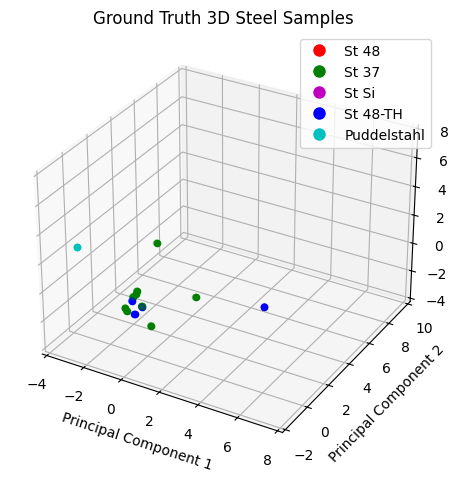

In [48]:
x = pca_wrong_rows[:, 0]
y = pca_wrong_rows[:, 1]
z = pca_wrong_rows[:, 2]



true_categories = y_test.iloc[row_numbers]
train_categories = y_train

rev_classes_dict = {0: "St 48", 1 : "St 37", 2 : "St Si", 3 : "St 48-TH", 4 : "Puddelstahl"}


class_colors = ['r', 'g', 'm', 'b', 'c']
classes = [0, 1, 2, 3, 4]

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

for i in range(len(x)):
        ax.scatter(x[i], y[i], z[i], c=class_colors[true_categories.iloc[i]], label=f'Category {true_categories.iloc[i]}')
        
#for i in range(len(x_tr)):
#        ax.scatter(x_tr[i], y_tr[i], z_tr[i], c=class_colors[train_categories.iloc[i]], label=f'Category {train_categories.iloc[i]}', alpha=0.1)


ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
ax.set_title('Ground Truth 3D Steel Samples')

legend_elements = []
for i in range(len(class_colors)):
    if i in classes:
        indices = np.where(true_categories == i)[0]
        ax.scatter(x[indices], y[indices], z[indices], c=class_colors[i], label= rev_classes_dict[i])
        legend_elements.append(Line2D([0], [0], marker='o', color='w', markerfacecolor=class_colors[i], markersize=10, label= rev_classes_dict[i]))

ax.set_xlim(-4, 8)
ax.set_ylim(-2, 10)
ax.set_zlim(-4, 8)

ax.legend(handles=legend_elements, loc='upper right')

#plt.savefig('GT_PCA_misclass_allpoints_XGBoost.jpg', format='jpg')

plt.tight_layout()
plt.show()

<br>

## 2. Resampled data from SMOTE-ENN

In [49]:
data = pd.read_csv("resampled_steel_data.csv")
data.head()

,C,Si,Mn,P,S,Cr,Ni,Al,Cu,steel_class
0,0.212333,0.148667,0.710167,0.025033,0.051967,0.066517,0.068783,0.002000,0.189833,0
1,0.173000,0.511833,1.020000,0.021300,0.037750,0.341333,0.099983,0.054183,0.407667,0
2,0.291000,0.231000,0.665000,0.023000,0.042000,0.006000,0.051000,0.002000,0.188000,0
3,0.210000,0.268667,0.547333,0.016300,0.037067,0.044467,0.067700,0.002000,0.133333,0
4,0.211333,0.309833,0.659333,0.021533,0.042283,0.032600,0.121000,0.002700,0.211333,0


In [50]:
# create X and y
X = data.drop(columns="steel_class")
y = data["steel_class"]

In [51]:
org_data = pd.read_csv("../../labeled_OES_data_2.csv")

# make data numeric

classes_dict = {"St 48" : 0, "St 37" : 1, "St Si" : 2, "St 48-TH" : 3, "Puddelstahl" : 4}
org_data["steel_class"] = [classes_dict[c] for c in org_data["steel_class"] ]

for column in org_data.columns:
        for index, value in org_data[column].items():
            if isinstance(value, str):
                org_data.at[index, column] = value.replace(",", ".")
org_data = org_data.map(pd.to_numeric)

X_org = org_data.iloc[:,:-1]
y_org = org_data.iloc[:,-1]

X_train_org, X_test_org, y_train_org, y_test_org = train_test_split(X_org, y_org, test_size=0.2, random_state=42)

In [52]:
# Given are steel types: St48, St 37, StSi, St 48-TH, Puddelstahl -> num_class = 5
# Note: in our Project num_classes is dependent on the supplied file which is used to train the model

# create Classifier
model_SMOTE_ENN = xgb.XGBClassifier(objective="multi:softmax", num_class=5, n_estimators=200, max_depth=2, learning_rate=0.01, gamma=0, reg_lambda=0)
model_SMOTE_ENN.fit(X, y)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=0, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.01, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=2, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None, num_class=5,
              num_parallel_tree=None, ...)

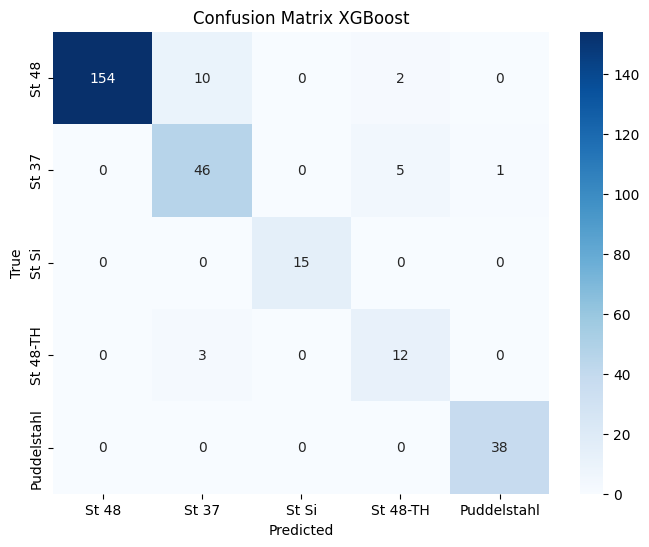

In [57]:
# build Confusion Matrix
conf_matrix = confusion_matrix(y_test_org, model_SMOTE_ENN.predict(X_test_org))
{"St 48" : 0, "St 37" : 1, "St Si" : 2, "St 48-TH" : 3, "Puddelstahl" : 4}
# print Confusion Martix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"], yticklabels=["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix XGBoost')
plt.savefig('Confusion_Matrix_XGBoost_Augmented_SMOTE_ENN.jpg', format='jpg')

plt.show()

In [54]:
n_prediction = model_SMOTE_ENN.predict(previously_misclassified_unlabeled)
correct = 0
for i in range(len(n_prediction)):
    print("Prediction: ", n_prediction[i], " - ", "GT: ", previous_label.iloc[i])
    if n_prediction[i] == previous_label.iloc[i]:
        correct += 1
print("In total correct: ", correct)

Prediction:  3  -  GT:  0
Prediction:  1  -  GT:  1
Prediction:  3  -  GT:  1
Prediction:  3  -  GT:  1
Prediction:  1  -  GT:  1
Prediction:  1  -  GT:  3
Prediction:  1  -  GT:  3
Prediction:  1  -  GT:  0
Prediction:  1  -  GT:  1
Prediction:  3  -  GT:  3
Prediction:  1  -  GT:  3
Prediction:  3  -  GT:  1
Prediction:  4  -  GT:  4
In total correct:  5


In [55]:
# Extract misclassified data samples
row_numbers = []
for i in range(len(predictions)):
    if predictions[i] != y_test_org.iloc[i]:
        row_numbers.append(i)

wrong_rows = X_test_org.iloc[row_numbers].copy()
wrong_rows.loc[:,"steel_type_true"] = y_test_org.iloc[row_numbers]
wrong_rows.loc[:,"steel_type_predicted"] = predictions[row_numbers]

print(wrong_rows)

             C        Si        Mn         P         S        Cr        Ni  \
123   0.304167  0.193333  0.634667  0.020700  0.041317  0.007033  0.049200   
1189  0.237000  0.005000  0.553000  0.048900  0.040100  0.005000  0.027300   
462   0.223250  0.005000  0.559750  0.055075  0.031350  0.005000  0.021800   
351   0.150800  0.809600  0.937200  0.018400  0.043160  0.011360  0.053420   
1009  0.136000  0.201000  0.524667  0.038617  0.040150  0.005200  0.029717   
...        ...       ...       ...       ...       ...       ...       ...   
259   0.230000  0.219333  0.475167  0.051150  0.054200  0.018117  0.029350   
548   0.257333  0.314000  0.593667  0.018000  0.052733  0.012000  0.042067   
1081  0.099350  0.981750  0.480000  0.034575  0.041612  0.009700  0.035112   
1127  0.120167  0.005000  0.330000  0.019467  0.031367  0.020483  0.107167   
429   0.235167  0.252000  0.680000  0.037600  0.047200  0.011983  0.030767   

            Al        Cu  steel_type_true  steel_type_predicted

In [56]:
new_labels = ["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"]
predictions_SMOTE_ENN = model_SMOTE_ENN.predict(X_test_org)
report = classification_report(y_test_org, predictions_SMOTE_ENN, target_names=new_labels)

print(report)

              precision    recall  f1-score   support

       St 48       1.00      0.93      0.96       166
       St 37       0.78      0.88      0.83        52
       St Si       1.00      1.00      1.00        15
    St 48-TH       0.63      0.80      0.71        15
 Puddelstahl       0.97      1.00      0.99        38

    accuracy                           0.93       286
   macro avg       0.88      0.92      0.90       286
weighted avg       0.94      0.93      0.93       286

